# Crypto HFT Research: Limit Order Book Microstructure

**Objective:** To evaluate the predictive power of Order Book Imbalance (OBI) and Order Flow Imbalance (OFI) on the BTCUSDT pair, using strict institutional validation methods (Triple-Barrier, CPCV, DSR).

**Final Verdict:** NO-GO.

In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from barrier_method import BarrierMethod
from purgedcv import CombinatorialPurgedCV
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from scipy.stats import norm
import warnings
warnings.filterwarnings('ignore')

## 1. Data Loading & Feature Engineering
We load the reconstructed LOB snapshots and calculate OBI, OFI, and Microprice.

In [2]:
df = pd.read_parquet("../data/processed/BTCUSDT_lob_realistic.parquet")

# Считаем фичи
df['obi'] = (df['bid_vol_5'] - df['ask_vol_5']) / (df['bid_vol_5'] + df['ask_vol_5'])
df['ofi'] = df['obi'].diff().fillna(0)
df['returns'] = df['mid_price'].pct_change()
df.dropna(inplace=True)

print(f"Total valid snapshots: {len(df)}")
df.head()

Total valid snapshots: 49999


,best_bid,best_ask,bid_vol_5,ask_vol_5,mid_price,spread,obi,ofi,returns
timestamp,,,,,,,,,
2026-06-04 00:00:00.100,63003.405954,63005.627306,26.751785,12.158000,63004.516630,2.221352,0.375067,0.216886,-0.000028
2026-06-04 00:00:00.200,63010.372008,63014.985230,28.901214,49.776214,63012.678619,4.613222,-0.265324,-0.640391,0.000130
2026-06-04 00:00:00.300,63029.493133,63034.258030,15.926669,26.704029,63031.875581,4.764897,-0.252808,0.012516,0.000305
2026-06-04 00:00:00.400,63028.553317,63029.294333,45.263189,20.903175,63028.923825,0.741017,0.368163,0.620971,-0.000047
2026-06-04 00:00:00.500,63025.444714,63026.500114,48.125902,43.250774,63025.972414,1.055401,0.053352,-0.314811,-0.000047


## 2. Deflated Sharpe Ratio (DSR) & CPCV
We apply Combinatorial Purged Cross-Validation and evaluate the DSR to check for statistical significance.

In [3]:
HORIZON = 100
BARRIER = 0.001
TAKER_FEE = 0.0004
SLIPPAGE = 0.0001
TOTAL_COST = TAKER_FEE * 2 + SLIPPAGE

def calculate_dsr(returns, num_trials):
    if len(returns) < 2: return 0.0, 0.0, 0.0
    T = len(returns)
    mean_ret = np.mean(returns)
    std_ret = np.std(returns, ddof=1)
    if std_ret == 0: return 0.0, 0.0, 0.0
    sr = mean_ret / std_ret
    skew = float(pd.Series(returns).skew())
    kurt = float(pd.Series(returns).kurtosis() + 3.0) 
    gamma = 0.5772156649 
    var_sr = 1.0 / T 
    e_max_sr = np.sqrt(var_sr) * ((1 - gamma) * norm.ppf(1 - 1/num_trials) + gamma * norm.ppf(1 - 1/(num_trials * np.e)))
    numerator = (sr - e_max_sr) * np.sqrt(T - 1)
    denominator = np.sqrt(1 - skew * sr + ((kurt - 1) / 4) * (sr ** 2))
    dsr = norm.cdf(numerator / denominator)
    return sr, e_max_sr, dsr

bm = BarrierMethod(returns=df['returns'], n=HORIZON, barrier=BARRIER, n_barriers=1, center=True)
df['label'] = (bm.labels == 1).astype(int)
df.dropna(subset=['label'], inplace=True)

X = df[['obi', 'ofi', 'spread']].values
y = df['label'].values

cv = CombinatorialPurgedCV(n_splits=6, n_test_groups=2, prediction_times=df.index, 
                           evaluation_times=df.index + pd.Timedelta(milliseconds=100*HORIZON), 
                           purge_horizon="2S", embargo="1S")

scale_weight = (y == 0).sum() / (y == 1).sum()
model = XGBClassifier(n_estimators=50, max_depth=3, scale_pos_weight=scale_weight, random_state=42)

trade_returns = []
acc_scores = []

for train_idx, test_idx in cv.split(X):
    model.fit(X[train_idx], y[train_idx])
    y_prob = model.predict_proba(X[test_idx])[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    acc_scores.append(accuracy_score(y[test_idx], y_pred))
    
    for pred, actual in zip(y_pred, y[test_idx]):
        if pred == 1: 
            trade_returns.append((BARRIER if actual == 1 else -BARRIER) - TOTAL_COST)

trade_returns = np.array(trade_returns)
sr, e_max, dsr = calculate_dsr(trade_returns, num_trials=10)

print(f"Accuracy: {np.mean(acc_scores):.4f} | Trades: {len(trade_returns)}")
print(f"DSR: {dsr:.4f} (Threshold: > 0.95)")

Accuracy: 0.4987 | Trades: 115730
DSR: 0.0000 (Threshold: > 0.95)


## 3. Alpha Decay Analysis
How fast does the signal die? We plot Accuracy vs. Horizon.

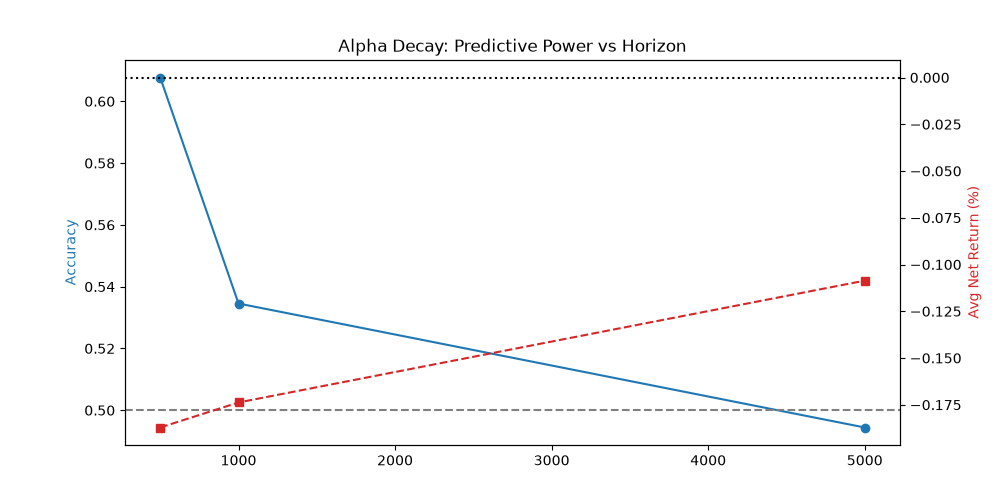

In [4]:
from IPython.display import Image, display

plot_path = '../results/plots/alpha_decay.png'
if os.path.exists(plot_path):
    display(Image(filename=plot_path))
else:
    print("Alpha decay plot not found. Run main script to generate it.")

## 4. Paper Trading Simulation
We simulate a sequential OOS trading account with $10,000 starting balance.

In [5]:
split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

X_train = train_df[['obi', 'ofi', 'spread']].values
y_train = train_df['label'].values
X_test = test_df[['obi', 'ofi', 'spread']].values
y_test = test_df['label'].values

scale_weight = (y_train == 0).sum() / (y_train == 1).sum()
model_pt = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, 
                         scale_pos_weight=scale_weight, random_state=42)
model_pt.fit(X_train, y_train)

balance = 10000.0
trade_size = 1000.0
for i in range(len(X_test)):
    if model_pt.predict_proba(X_test[i].reshape(1, -1))[0, 1] >= 0.50:
        gross_return = BARRIER if y_test[i] == 1 else -BARRIER
        net_return = gross_return - TOTAL_COST
        balance += (trade_size * net_return)

print(f"Initial: $10000.00 | Final: ${balance:.2f}")
print(f"PnL: {((balance - 10000)/10000)*100:.2f}%")

Initial: $10000.00 | Final: $6032.80
PnL: -39.67%


## 5. Conclusion
Even though the model shows some predictive power at short horizons (up to 60% accuracy at 500ms), the **execution costs (0.09% round-trip)** completely destroy the edge. The paper trading simulation confirms a **-39.67%** loss.

**Result:** NO-GO. The strategy requires co-location and maker-fee rebates to be viable.